# Day 3 · A review threshold you can defend

A model gives scores, but a review team needs a rule: *flag this request or not*. Today we compare three ways of handling the rare default class, then pick a threshold using a teaching loss (`10 x FN + FP`) and a review capacity of 12% of requests per validation period.

## 1. Setup

In [1]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
RAW_BASE = "https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)

setup_path = ROOT / "scripts" / "setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    for attempt in range(3):
        try:
            with urllib.request.urlopen(f"{RAW_BASE}/{COURSE_REVISION}/scripts/setup_colab.py", timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_path))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise

    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)

FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified

DAY2_REVISION = "1e1da4acbee8941bef07245b259fb6c27ced4ad7"
DAY2_SHA256 = "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"
fetch_verified(f"{RAW_BASE}/{DAY2_REVISION}/scripts/day2_validation.py",
               ROOT / "scripts/day2_validation.py", DAY2_SHA256)

LAB_REVISION = "c2dc52e129878d0d487db1874891c658de7c4d0d"
SUPPORT_HASHES = {
    "scripts/day3_decision.py": "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12",
    "data/day3_oof_example.csv": "659952bef85ac3b7ceb7ab84eb2102de6c9b433a1ba122cd57df96581baf0eb3",
    "data/day3_oof_example.json": "920cf9830043afcc83f8c276c8945677296eb3c49a6e69326d47f6080a9e7fad",
}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"{RAW_BASE}/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 3 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 3 setup verified


## 2. Fix the policy before looking at results

The target is a default within 90 days of applying. Two rules are frozen up front: a missed default (FN) costs 10 teaching units and a false alarm (FP) costs 1, and no validation period may flag more than 12% of its requests. Folds are the same later-period folds as Day 2, so training only sees mature labels from other customers.

In [2]:
import json
import os
import platform
import zipfile
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from data_checks import validate_frame
from day2_validation import deduplicate_applications, make_time_group_split
from day3_decision import (
    STRATEGIES, TARGET, CostPolicy, DecisionConfig, TrainingBudgetExpired,
    flag_at, generate_oof, load_example, period_audit, reflection_check,
    region_audit, select_threshold, threshold_sweep, validate_oof
)

contract = json.loads(
    (ROOT / "data/data_contract.json").read_text(encoding="utf-8")
)

train, duplicates = deduplicate_applications(
    pd.read_csv(ROOT / "data/tamweel_train.csv")
)

validate_frame(train, contract, "train")

config = DecisionConfig(trees=80 if FAST_MODE else 160)
policy = CostPolicy(**contract["decision_policy"])

STRATEGY_FOR_DECISION = "weighted"
USE_EXAMPLE = False
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"

assert STRATEGY_FOR_DECISION in STRATEGIES

ARTIFACTS, REPORTS = ROOT / "artifacts", ROOT / "reports"
ARTIFACTS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)

folds = make_time_group_split(
    train,
    horizon_days=contract["target"]["horizon_days"]
)

style_settings = [
    {
        "selector": "th",
        "props": [
            ("background-color", "#F2F5F8"),
            ("color", "#344054"),
            ("font-weight", "600"),
            ("text-align", "center"),
            ("border", "1px solid #D0D5DD"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("padding", "9px"),
            ("border", "1px solid #E8EDF2")
        ]
    },
    {
        "selector": "caption",
        "props": [
            ("caption-side", "top"),
            ("font-size", "14px"),
            ("font-weight", "600"),
            ("color", "#344054"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "table",
        "props": [
            ("border-collapse", "collapse"),
            ("width", "100%")
        ]
    }
]

summary = pd.DataFrame([{
    "training_rows": len(train),
    "positive_rate": train[TARGET].mean(),
    "FN_units": policy.false_negative_cost,
    "FP_units": policy.false_positive_cost,
    "capacity_per_period": policy.max_flag_fraction,
    "trees_per_model": config.trees
}])

display(
    summary.style
    .format({
        "training_rows": "{:,.0f}",
        "positive_rate": "{:.2%}",
        "FN_units": "{:,.0f}",
        "FP_units": "{:,.0f}",
        "capacity_per_period": "{:.1%}",
        "trees_per_model": "{:,.0f}"
    })
    .set_caption("Day 3 | Training and Decision Configuration")
    .set_table_styles(style_settings)
    .hide(axis="index")
)

fold_audit = pd.DataFrame([
    fold["audit"] for fold in folds
])

display(
    fold_audit.style
    .format(precision=4)
    .set_caption("Time-Based Validation Fold Audit")
    .set_table_styles(style_settings)
    .hide(axis="index")
)

training_rows,positive_rate,FN_units,FP_units,capacity_per_period,trees_per_model
"10,000",7.89%,10,1,12.0%,80


fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available
1,2023-07-01,2024-01-01,3223,1632,274,110,826,912,0,2023-06-30
2,2024-01-01,2024-07-01,4460,1674,353,135,785,1348,0,2023-12-31
3,2024-07-01,2025-01-01,5731,1733,465,139,861,1675,0,2024-06-30


## 3. Change only the training, never the validation

Three LightGBM strategies share the same features, folds, tree budget and seed. They differ only in how the rare default class is treated during training: **unweighted**, **class-weighted**, **oversampled**. Validation rows are never reweighted or resampled.

In [3]:
fallback_reason = None

if not USE_EXAMPLE:
    try:
        oof, model_report, provenance = generate_oof(train, contract, config)
    except TrainingBudgetExpired as exc:
        if ASSESSMENT_MODE:
            raise
        USE_EXAMPLE, fallback_reason = True, str(exc)

if USE_EXAMPLE:
    oof, example_info = load_example(
        ROOT / "data/day3_oof_example.csv",
        ROOT / "data/day3_oof_example.json",
        train,
        folds,
        assessment_mode=ASSESSMENT_MODE
    )

    model_report = pd.DataFrame(example_info["model_report"])

    provenance = {
        "source": "EDUCATIONAL_EXAMPLE",
        "example_metadata": example_info,
        "fallback_reason": fallback_reason or "Learner selected discussion example"
    }

SOURCE = oof.source.iloc[0]

effective_config = example_info["config"] if USE_EXAMPLE else asdict(config)

coverage = validate_oof(oof, train, folds)

style_settings = [
    {
        "selector": "th",
        "props": [
            ("background-color", "#F2F5F8"),
            ("color", "#344054"),
            ("font-weight", "600"),
            ("text-align", "center"),
            ("border", "1px solid #D0D5DD"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("color", "#E2E8F0"),
            ("text-align", "center"),
            ("padding", "9px"),
            ("border", "1px solid #E8EDF2")
        ]
    },
    {
        "selector": "caption",
        "props": [
            ("caption-side", "top"),
            ("font-size", "14px"),
            ("font-weight", "600"),
            ("color", "#E2E8F0"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "table",
        "props": [
            ("border-collapse", "collapse"),
            ("width", "100%")
        ]
    }
]

print(
    "LIVE: your own CPU run"
    if SOURCE == "LIVE"
    else "EDUCATIONAL_EXAMPLE: discussion only, not submittable"
)

display(
    pd.DataFrame([coverage]).style
    .format(precision=4)
    .set_caption("OOF Coverage Validation")
    .set_table_styles(style_settings)
    .hide(axis="index")
)

display(
    model_report[
        [
            "strategy",
            "fold",
            "original_training_rows",
            "fitted_rows",
            "scale_pos_weight",
            "training_positive_rate",
            "fitted_positive_rate",
            "average_precision",
            "train_seconds",
            "source"
        ]
    ].style
    .format(precision=4)
    .set_caption("Model Training Report")
    .set_table_styles(style_settings)
    .hide(axis="index")
)

decision_oof = oof[oof.strategy.eq(STRATEGY_FOR_DECISION)].copy()

assert decision_oof.application_id.is_unique

print(f"Strategy declared before the comparison: {STRATEGY_FOR_DECISION}")

LIVE: your own CPU run


eligible_rows,all_rows,whole_data_coverage,eligible_coverage,warmup_without_oof,source
5039,10000,0.5039,1.0000,4961,LIVE


strategy,fold,original_training_rows,fitted_rows,scale_pos_weight,training_positive_rate,fitted_positive_rate,average_precision,train_seconds,source
unweighted,1,3223,3223,1.0000,0.0850,0.0850,0.3395,0.4349,LIVE
weighted,1,3223,3223,10.7628,0.0850,0.0850,0.3378,0.2318,LIVE
oversampled,1,3223,5898,1.0000,0.0850,0.5000,0.3502,1.1966,LIVE
unweighted,2,4460,4460,1.0000,0.0791,0.0791,0.3403,1.8444,LIVE
weighted,2,4460,4460,11.6346,0.0791,0.0791,0.3295,0.1918,LIVE
oversampled,2,4460,8214,1.0000,0.0791,0.5000,0.3390,0.6285,LIVE
unweighted,3,5731,5731,1.0000,0.0811,0.0811,0.2661,0.3509,LIVE
weighted,3,5731,5731,11.3247,0.0811,0.0811,0.2707,0.2890,LIVE
oversampled,3,5731,10532,1.0000,0.0811,0.5000,0.2776,0.5961,LIVE


Strategy declared before the comparison: weighted


## 4. Accuracy can hide a failure

Every strategy scores the same 5,039 later requests (4,961 warm-up rows have no out-of-fold prediction). With only about 8% defaults, a model that flags almost nobody still looks accurate. So we read accuracy next to recall, precision, flag counts and loss at the default 0.5 threshold, and compare against "flag nobody".

strategy,rows,positive_rate,pooled_roc_auc,pooled_ap,accuracy_at_0_5,recall_at_0_5,precision_at_0_5,flags_at_0_5,loss_at_0_5,capacity_ok_at_0_5,source
unweighted,5039,0.0762,0.7979,0.3091,0.9256,0.1250,0.5517,87,3399,True,LIVE
weighted,5039,0.0762,0.7969,0.3100,0.8125,0.5781,0.2209,1005,2403,False,LIVE
oversampled,5039,0.0762,0.7979,0.3159,0.8073,0.5990,0.2197,1047,2357,False,LIVE


rule,rows,accuracy,recall,precision,loss_units
Flag nobody,5039,0.9238,0.0000,None,3840


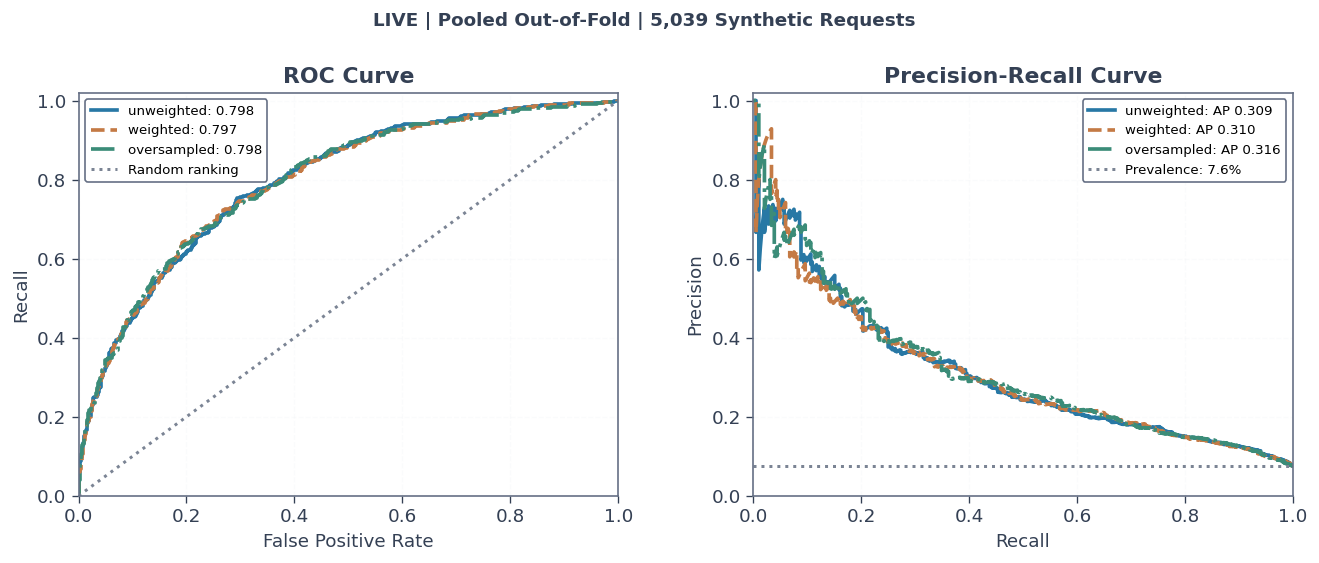

In [4]:
summary_rows = []

for strategy, part in oof.groupby("strategy", sort=False):
    at_half = threshold_sweep(part, policy).query("threshold == 0.5").iloc[0]

    summary_rows.append({
        "strategy": strategy,
        "rows": len(part),
        "positive_rate": part[TARGET].mean(),
        "pooled_roc_auc": roc_auc_score(part[TARGET], part.probability),
        "pooled_ap": average_precision_score(part[TARGET], part.probability),
        "accuracy_at_0_5": at_half.accuracy,
        "recall_at_0_5": at_half.recall,
        "precision_at_0_5": at_half.precision,
        "flags_at_0_5": at_half.flagged,
        "loss_at_0_5": at_half.loss_units,
        "capacity_ok_at_0_5": at_half.capacity_feasible,
        "source": SOURCE
    })

strategy_table = pd.DataFrame(summary_rows)

table_style = [
    {
        "selector": "th",
        "props": [
            ("background-color", "#F2F5F8"),
            ("color", "#344054"),
            ("font-weight", "600"),
            ("text-align", "center"),
            ("border", "1px solid #D0D5DD"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("color", "#E2E8F0"),
            ("text-align", "center"),
            ("padding", "9px"),
            ("border", "1px solid #E8EDF2")
        ]
    },
    {
        "selector": "caption",
        "props": [
            ("caption-side", "top"),
            ("font-size", "14px"),
            ("font-weight", "600"),
            ("color", "#E2E8F0"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "table",
        "props": [
            ("border-collapse", "collapse"),
            ("width", "100%")
        ]
    }
]

display(
    strategy_table.style
    .format(precision=4)
    .set_caption("Strategy Performance Comparison")
    .set_table_styles(table_style)
    .hide(axis="index")
)

flag_nobody = {
    "rule": "Flag nobody",
    "rows": len(decision_oof),
    "accuracy": 1 - decision_oof[TARGET].mean(),
    "recall": 0.0,
    "precision": None,
    "loss_units": int(decision_oof[TARGET].sum()) * policy.false_negative_cost
}

display(
    pd.DataFrame([flag_nobody]).style
    .format(precision=4)
    .set_caption("Baseline: Flag Nobody")
    .set_table_styles(table_style)
    .hide(axis="index")
)

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.2
})

palette = {
    "unweighted": "#2878A5",
    "weighted": "#C47A45",
    "oversampled": "#3B8C78"
}

fig, (ax_roc, ax_pr) = plt.subplots(
    1, 2,
    figsize=(11.5, 4.8),
    constrained_layout=False
)

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    top=0.84,
    bottom=0.14,
    wspace=0.25
)

for strategy, dash in zip(STRATEGIES, ["-", "--", "-."]):
    part = oof[oof.strategy.eq(strategy)]

    fpr, tpr, _ = roc_curve(
        part[TARGET],
        part.probability
    )

    prec, rec, _ = precision_recall_curve(
        part[TARGET],
        part.probability
    )

    stats = strategy_table.set_index("strategy").loc[strategy]

    ax_roc.plot(
        fpr,
        tpr,
        color=palette[strategy],
        linestyle=dash,
        linewidth=2.2,
        label=f"{strategy}: {stats.pooled_roc_auc:.3f}"
    )

    ax_pr.plot(
        rec,
        prec,
        color=palette[strategy],
        linestyle=dash,
        linewidth=2.2,
        label=f"{strategy}: AP {stats.pooled_ap:.3f}"
    )

ax_roc.plot(
    [0, 1], [0, 1],
    color="#7B8494",
    linestyle=":",
    linewidth=1.8,
    label="Random ranking"
)

ax_pr.axhline(
    decision_oof[TARGET].mean(),
    color="#7B8494",
    linestyle=":",
    linewidth=1.8,
    label=f"Prevalence: {decision_oof[TARGET].mean():.1%}"
)

ax_roc.set(
    title="ROC Curve",
    xlabel="False Positive Rate",
    ylabel="Recall",
    xlim=(0, 1),
    ylim=(0, 1.02)
)

ax_pr.set(
    title="Precision-Recall Curve",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1.02)
)

for ax in (ax_roc, ax_pr):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#667085")
        spine.set_linewidth(1.0)

    ax.grid(
        axis="both",
        color="#E8EDF2",
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="both",
        colors="#344054",
        width=0.8,
        length=4
    )

    ax.title.set_color("#344054")
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_color("#344054")
    ax.yaxis.label.set_color("#344054")

    ax.legend(
        loc="best",
        fontsize=8,
        frameon=True,
        facecolor="white",
        edgecolor="#667085",
        framealpha=1
    )

fig.suptitle(
    f"{SOURCE} | Pooled Out-of-Fold | "
    f"{len(decision_oof):,} Synthetic Requests",
    fontsize=11,
    fontweight="bold",
    color="#344054"
)

fig.savefig(
    ARTIFACTS / "day3_roc_pr.png",
    dpi=180,
    bbox_inches=None,
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 5. Sweep every distinct decision rule

A request is flagged when `score >= threshold`. The sweep tries every distinct score as a threshold and records TP, FP, FN, TN, recall, precision, the loss, and the flag share per period. We then read three rules side by side: the default 0.5, the minimum loss with no capacity limit, and the minimum loss that keeps **every** period within 12%.

rule,threshold,tp,fp,fn,tn,recall,precision,flagged,flag_fraction,loss_units,loss_units_per_10000,capacity_feasible
Default 0.5,0.500000,222,783,162,3872,0.578100,0.220900,1005,0.199400,2403,4768.803300,False
"Minimum loss, no capacity limit",0.448600,246,895,138,3760,0.640600,0.215600,1141,0.226400,2275,4514.784700,False
"Minimum loss, every-period capacity",0.658300,157,369,227,4286,0.408900,0.298500,526,0.104400,2639,5237.150200,True


Capped minus default loss: +236 teaching units. 0.5 feasible: False
Exact rule to keep in the JSON: 0.6583471436014694 with >=


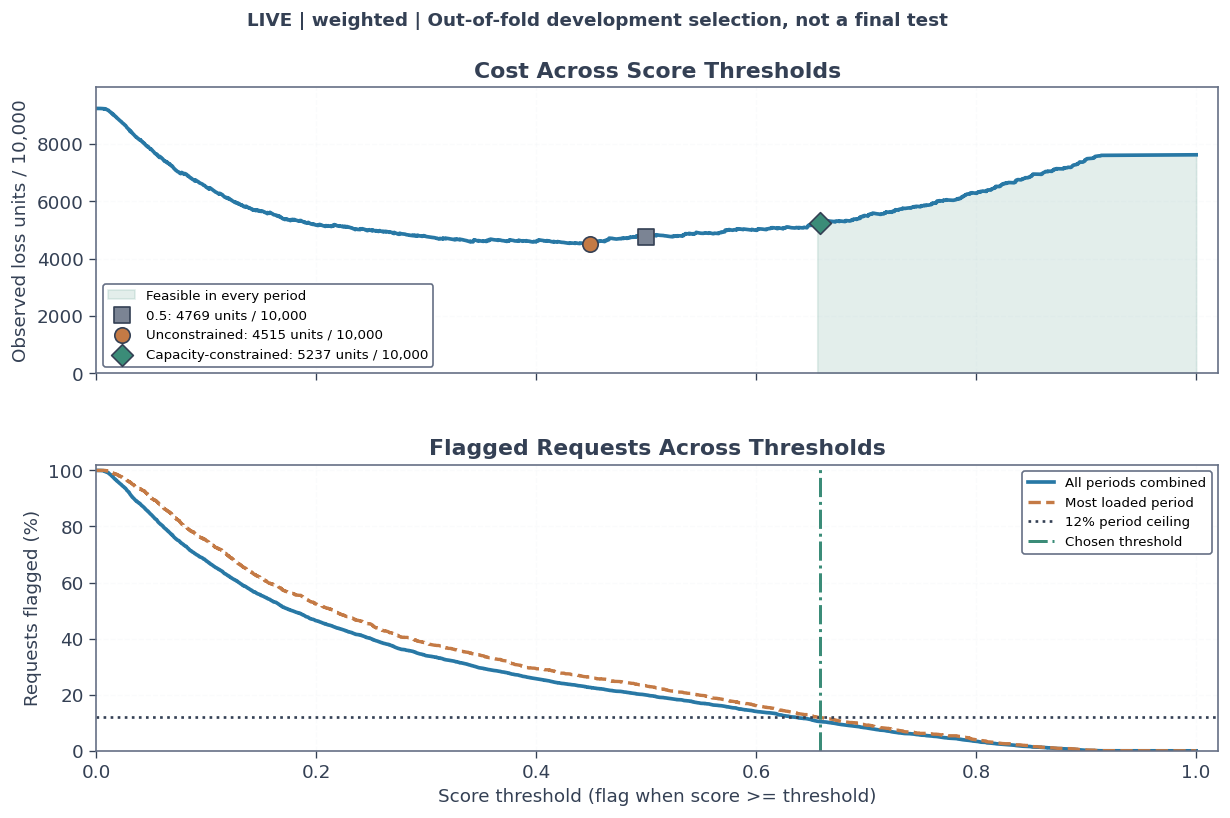

In [5]:
sweep = threshold_sweep(decision_oof, policy)
free_pt = select_threshold(sweep, constrained=False)
capped_pt = select_threshold(sweep, constrained=True)
default_pt = sweep.loc[sweep.threshold.eq(0.5)].iloc[0].to_dict()

operating_points = pd.DataFrame([
    {**point, "rule": label} for label, point in [
        ("Default 0.5", default_pt),
        ("Minimum loss, no capacity limit", free_pt),
        ("Minimum loss, every-period capacity", capped_pt)
    ]
])

display(
    operating_points[[
        "rule", "threshold", "tp", "fp", "fn", "tn", "recall", "precision",
        "flagged", "flag_fraction", "loss_units", "loss_units_per_10000",
        "capacity_feasible"
    ]].round(4).style
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#F2F5F8"),
                ("color", "#344054"),
                ("font-weight", "600"),
                ("text-align", "center"),
                ("border", "1px solid #D0D5DD"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("color", "#E2E8F0"),
                ("text-align", "center"),
                ("padding", "9px"),
                ("border", "1px solid #E8EDF2")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]
        }
    ])
    .hide(axis="index")
)

assert free_pt["loss_units"] <= default_pt["loss_units"]

if default_pt["capacity_feasible"]:
    assert capped_pt["loss_units"] <= default_pt["loss_units"]

period_table = period_audit(
    decision_oof, capped_pt["threshold"], policy
)
assert period_table.within_capacity.all()

loss_delta = capped_pt["loss_units"] - default_pt["loss_units"]

print(
    f"Capped minus default loss: {loss_delta:+.0f} teaching units. "
    f"0.5 feasible: {default_pt['capacity_feasible']}"
)
print(
    "Exact rule to keep in the JSON:",
    repr(capped_pt["threshold"]), "with >="
)

COLORS = {
    "main": "#2878A5",
    "feasible": "#3B8C78",
    "unconstrained": "#C47A45",
    "default": "#7B8494",
    "capacity": "#344054",
    "edge": "#344054",
    "text": "#344054",
    "grid": "#E8EDF2",
    "axis": "#667085"
}

fig, (ax_loss, ax_flags) = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True,
    constrained_layout=False
)

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    top=0.89,
    bottom=0.10,
    hspace=0.32
)

ax_loss.plot(
    sweep.threshold,
    sweep.loss_units_per_10000,
    color=COLORS["main"],
    linewidth=2.2
)

ax_loss.fill_between(
    sweep.threshold,
    0,
    sweep.loss_units_per_10000,
    where=sweep.capacity_feasible,
    color=COLORS["feasible"],
    alpha=0.14,
    label="Feasible in every period"
)

operating_markers = [
    ("0.5", default_pt, "s", COLORS["default"]),
    ("Unconstrained", free_pt, "o", COLORS["unconstrained"]),
    ("Capacity-constrained", capped_pt, "D", COLORS["feasible"])
]

for label, point, marker, color in operating_markers:
    ax_loss.scatter(
        point["threshold"],
        point["loss_units_per_10000"],
        marker=marker,
        s=85,
        color=color,
        edgecolor=COLORS["edge"],
        linewidth=1.0,
        zorder=5,
        label=f"{label}: {point['loss_units_per_10000']:.0f} units / 10,000"
    )

ax_loss.set(
    ylabel="Observed loss units / 10,000",
    title="Cost Across Score Thresholds"
)

ax_loss.set_xlim(0, 1.02)

loss_max = sweep.loss_units_per_10000.max()
ax_loss.set_ylim(0, max(1, loss_max * 1.08))

ax_loss.legend(
    loc="best",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor=COLORS["axis"],
    framealpha=1
)

ax_flags.plot(
    sweep.threshold,
    sweep.flag_fraction * 100,
    color=COLORS["main"],
    linewidth=2.2,
    label="All periods combined"
)

ax_flags.plot(
    sweep.threshold,
    sweep.max_period_flag_fraction * 100,
    color=COLORS["unconstrained"],
    linewidth=2.0,
    linestyle="--",
    label="Most loaded period"
)

ax_flags.axhline(
    policy.max_flag_fraction * 100,
    color=COLORS["capacity"],
    linewidth=1.6,
    linestyle=":",
    label="12% period ceiling"
)

ax_flags.axvline(
    capped_pt["threshold"],
    color=COLORS["feasible"],
    linewidth=1.8,
    linestyle="-.",
    label="Chosen threshold"
)

ax_flags.set(
    xlabel="Score threshold (flag when score >= threshold)",
    ylabel="Requests flagged (%)",
    title="Flagged Requests Across Thresholds"
)

ax_flags.set_xlim(0, 1.02)
ax_flags.set_ylim(0, 102)

ax_flags.legend(
    loc="best",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor=COLORS["axis"],
    framealpha=1
)

for ax in (ax_loss, ax_flags):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLORS["axis"])
        spine.set_linewidth(1.0)

    ax.grid(
        axis="both",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="both",
        colors=COLORS["text"],
        width=0.8,
        length=4
    )

    ax.title.set_color(COLORS["text"])
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_color(COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])

fig.suptitle(
    f"{SOURCE} | {STRATEGY_FOR_DECISION} | "
    "Out-of-fold development selection, not a final test",
    fontsize=11,
    fontweight="bold",
    color=COLORS["text"]
)

fig.savefig(
    ARTIFACTS / "cost_curve.png",
    dpi=180,
    bbox_inches=None,
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 6. Check every period and test the policy's sensitivity

The per-period table is the binding capacity evidence; one pooled rate is not enough. The sensitivity table repeats the choice with the miss cost at 8, 10 and 12 units. The textbook threshold 1/11 (about 0.0909) needs calibrated probabilities and no capacity limit, so it is **not** imposed on today's class-weighted raw scores.

In [6]:
display(
    period_table.style
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#F2F5F8"),
                ("color", "#344054"),
                ("font-weight", "600"),
                ("text-align", "center"),
                ("border", "1px solid #D0D5DD"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("color", "#E2E8F0"),
                ("text-align", "center"),
                ("padding", "9px"),
                ("border", "1px solid #E8EDF2")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]
        }
    ])
    .hide(axis="index")
)

scenario_rows = []
for miss_cost in [8.0, 10.0, 12.0]:
    alt_policy = replace(policy, false_negative_cost=miss_cost)
    alt = select_threshold(threshold_sweep(decision_oof, alt_policy))
    scenario_rows.append({
        "FN_loss_units": miss_cost, "FP_loss_units": policy.false_positive_cost,
        "capacity_fraction": policy.max_flag_fraction, "threshold": alt["threshold"],
        "flagged": alt["flagged"], "recall": alt["recall"], "loss_units": alt["loss_units"],
        "capacity_feasible": alt["capacity_feasible"], "source": SOURCE})
sensitivity = pd.DataFrame(scenario_rows)

display(
    sensitivity.round(4).style
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#F2F5F8"),
                ("color", "#344054"),
                ("font-weight", "600"),
                ("text-align", "center"),
                ("border", "1px solid #D0D5DD"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("color", "#E2E8F0"),
                ("text-align", "center"),
                ("padding", "9px"),
                ("border", "1px solid #E8EDF2")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]
        }
    ])
    .hide(axis="index")
)

print("Capacity, not the cost ratio, is what pins the threshold here: the three scenarios share one cut-off.")

fold,rows,capacity,flagged,flag_fraction,within_capacity,source
1,1632,195,137,0.083946,True,LIVE
2,1674,200,183,0.109319,True,LIVE
3,1733,207,206,0.118869,True,LIVE


FN_loss_units,FP_loss_units,capacity_fraction,threshold,flagged,recall,loss_units,capacity_feasible,source
8.000000,1,0.120000,0.658300,526,0.408900,2185.000000,True,LIVE
10.000000,1,0.120000,0.658300,526,0.408900,2639.000000,True,LIVE
12.000000,1,0.120000,0.658300,526,0.408900,3093.000000,True,LIVE


Capacity, not the cost ratio, is what pins the threshold here: the three scenarios share one cut-off.


## 7. Compare regions, descriptively

With one shared threshold frozen, each synthetic region's false-positive rate is `FP / (FP + TN)`. Gaps are descriptive only: no confidence interval, no fairness certificate.

region,rows,negatives,positives,flagged,false_positives,true_positives,false_positive_rate,recall,low_negative_support,source
central,1184,1088,96,131,88,43,0.080900,0.447900,False,LIVE
western,1262,1158,104,132,96,36,0.082900,0.346200,False,LIVE
eastern,1295,1192,103,131,92,39,0.077200,0.378600,False,LIVE
other,1298,1217,81,132,93,39,0.076400,0.481500,False,LIVE


False-positive-rate gap (percentage points): 0.6484134519182061


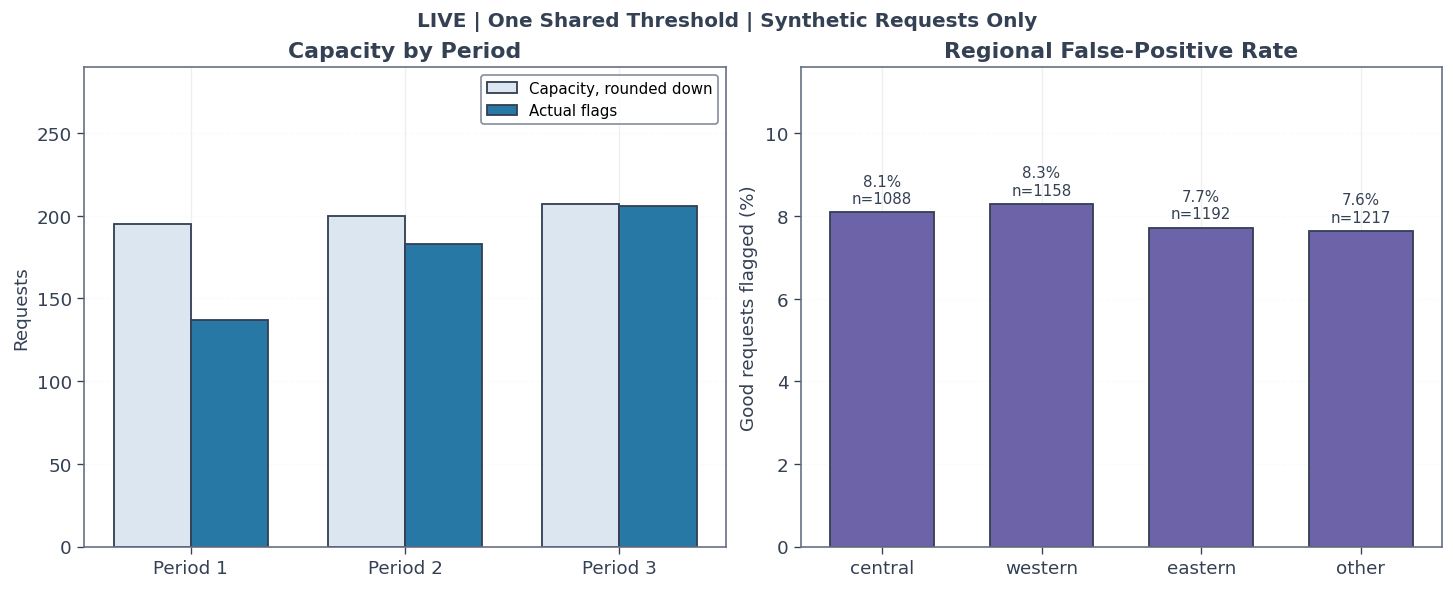

In [7]:
region_table, gap_info = region_audit(
    decision_oof,
    capped_pt["threshold"]
)

display(
    region_table.round(4).style
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#F2F5F8"),
                ("color", "#344054"),
                ("font-weight", "600"),
                ("text-align", "center"),
                ("border", "1px solid #D0D5DD"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("color", "#E2E8F0"),
                ("text-align", "center"),
                ("padding", "9px"),
                ("border", "1px solid #E8EDF2")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]
        }
    ])
    .hide(axis="index")
)

print(
    "False-positive-rate gap (percentage points):",
    gap_info["fpr_gap_percentage_points"]
)

COLORS = {
    "capacity": "#DCE6F1",
    "flagged": "#2878A5",
    "regional": "#6C63A8",
    "edge": "#344054",
    "text": "#344054",
    "grid": "#E8EDF2",
    "axis": "#667085"
}

fig, (ax_cap, ax_reg) = plt.subplots(
    1, 2,
    figsize=(12, 4.8),
    constrained_layout=True
)

pos = np.arange(len(period_table))

ax_cap.bar(
    pos - 0.18,
    period_table.capacity,
    0.36,
    color=COLORS["capacity"],
    edgecolor=COLORS["edge"],
    linewidth=1.1,
    label="Capacity, rounded down"
)

ax_cap.bar(
    pos + 0.18,
    period_table.flagged,
    0.36,
    color=COLORS["flagged"],
    edgecolor=COLORS["edge"],
    linewidth=1.1,
    label="Actual flags"
)

ax_cap.set(
    xticks=pos,
    xticklabels=[f"Period {n}" for n in period_table.fold],
    ylabel="Requests",
    title="Capacity by Period"
)

ax_cap.set_ylim(
    0,
    period_table.capacity.max() * 1.4
)

ax_cap.legend(
    frameon=True,
    facecolor="white",
    edgecolor=COLORS["axis"],
    fontsize=9
)

regional_values = (
    region_table.false_positive_rate * 100
)

ax_reg.bar(
    region_table.region,
    regional_values,
    color=COLORS["regional"],
    edgecolor=COLORS["edge"],
    linewidth=1.1,
    width=0.65
)

ax_reg.set(
    ylabel="Good requests flagged (%)",
    title="Regional False-Positive Rate"
)

for i, row in enumerate(region_table.itertuples()):
    if pd.notna(row.false_positive_rate):
        ax_reg.text(
            i,
            row.false_positive_rate * 100 + 0.15,
            f"{row.false_positive_rate:.1%}\nn={row.negatives}",
            ha="center",
            va="bottom",
            fontsize=9,
            color=COLORS["text"]
        )

ax_reg.set_ylim(
    0,
    max(10, regional_values.max() * 1.4)
)

for ax in (ax_cap, ax_reg):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLORS["axis"])
        spine.set_linewidth(1.0)
    ax.grid(
        axis="y",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="--"
    )
    ax.set_axisbelow(True)
    ax.tick_params(
        axis="both",
        colors=COLORS["text"],
        width=0.8,
        length=4
    )

    ax.title.set_color(COLORS["text"])
    ax.title.set_fontweight("bold")

    ax.xaxis.label.set_color(COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])

fig.suptitle(
    f"{SOURCE} | One Shared Threshold | Synthetic Requests Only",
    fontsize=12,
    fontweight="bold",
    color=COLORS["text"]
)

fig.savefig(
    ARTIFACTS / "day3_capacity_regions.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 8. Reasoning

In [8]:
responses = {
    "threshold_reason": (
        "I chose 0.6583 because it is the lowest-loss threshold at which every validation period stays within "
        "the 12% review capacity. It flags 526 of 5,039 requests (10.4%; the busiest period is 11.9%) with "
        "recall 40.9% and precision 29.9%. The policy (FN = 10 units, FP = 1 unit, 12% per period) was fixed "
        "before I looked at any result."),
    "cost_capacity_tradeoff": (
        "The cheapest rule without a capacity limit is 0.4486 with 2,275 units, but it flags 22.6% of requests "
        "and breaks capacity (busiest period 26.3%). The default 0.5 costs 2,403 units and also breaks capacity "
        "(19.9% flagged, busiest period 23.2%). The capacity-safe 0.6583 costs 2,639 units, which is 236 units "
        "more than 0.5, so staying within the review team's limit costs about 9.8% extra teaching loss and "
        "catches fewer defaults (227 missed instead of 162)."),
    "regional_gap": (
        "False-positive rates are 8.09% (central), 8.29% (western), 7.72% (eastern) and 7.64% (other), a gap of "
        "0.65 percentage points on 1,088 to 1,217 good requests per region. Recall differs more, from 34.6% "
        "(western) to 48.2% (other), and the groups are small. This is descriptive: it has no confidence "
        "interval and is not a fairness check, so the regional recall difference deserves a closer look."),
    "limitations": (
        "The threshold and its loss are estimated on the same out-of-fold outcomes, so this is development "
        "selection and not a final test. The out-of-fold data covers 50.39% of the training rows (4,961 warm-up "
        "rows have no prediction). Class weights make the scores uncalibrated, so the textbook threshold of "
        "1/11 does not apply. The loss matrix is a simplified teaching policy in units, not money, and one "
        "flag means 'send to review', not a rejection."),
    "why_accuracy_misleads": (
        "Only 7.6% of requests are defaults, so flagging nobody already gives 92.4% accuracy while catching "
        "no default at all (loss 3,840 units). At 0.5 the weighted model has lower accuracy (81.3%) but much "
        "better recall (57.8%), and the unweighted model has the highest accuracy (92.6%) with only 12.5% "
        "recall. Accuracy hides which kind of error is being made, so I read recall, precision and the loss "
        "next to it."),
    "why_oof": (
        "Training predictions are scored on rows the model has already seen, so they are too optimistic. "
        "Out-of-fold predictions come from models that never saw those rows, from later periods, and with "
        "validation customers removed from training, so they imitate new requests. The challenge data must stay "
        "untouched for the final check and cannot be used to pick a threshold."),
}
checkpoint = reflection_check(responses, SOURCE)
print(checkpoint["status"], "| missing:", checkpoint["missing"])

READY_FOR_REVIEW | missing: []


## 9. Export the evidence

In [9]:
NL = chr(10)


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


checkpoint = reflection_check(responses, SOURCE)
status = "TECHNICAL_READY" if SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE"
pooled_ap = float(average_precision_score(decision_oof[TARGET], decision_oof.probability))

threshold_metrics = {
    "source": SOURCE, "technical_status": status, "strategy": STRATEGY_FOR_DECISION,
    "policy": asdict(policy), "unit": "educational_loss_unit", "comparison_operator": ">=",
    "capacity_scope": "every validation period; floor(fraction * period_rows)",
    "chosen": capped_pt, "unconstrained": free_pt, "default_0_5": default_pt,
    "loss_change_vs_default": loss_delta, "pooled_oof_ap": pooled_ap, "regional_audit": gap_info,
    "coverage": coverage, "selection_status": "OOF development selection; not an independent final test"}

membership = train[["application_id", "application_date"]].copy()
membership["role"], membership["fold"] = "warmup_no_oof", 0
for fold in folds:
    membership.loc[fold["valid"], "role"] = "eligible_oof"
    membership.loc[fold["valid"], "fold"] = fold["audit"]["fold"]
membership["source"] = SOURCE

review_flags = decision_oof.copy()
review_flags["review_flag"] = flag_at(decision_oof.probability, capped_pt["threshold"]).astype(int)

tables = {
    "day3_model_report.csv": model_report, "day3_model_comparison.csv": strategy_table,
    "day3_oof_predictions.csv": oof, "day3_oof_coverage.csv": membership,
    "threshold_sweep.csv": sweep, "day3_period_capacity.csv": period_table,
    "day3_region_audit.csv": region_table, "day3_cost_sensitivity.csv": sensitivity,
    "day3_review_flags.csv": review_flags}
for name, frame in tables.items():
    frame.to_csv(ARTIFACTS / name, index=False)

run_info = {
    "technical_status": status, "learner_status": checkpoint["status"], "source": SOURCE,
    "requested_config": asdict(config), "effective_config": effective_config,
    "assessment_mode": ASSESSMENT_MODE, "data_revision": COURSE_REVISION, "lab_revision": LAB_REVISION,
    "support_sha256": SUPPORT_HASHES, "day2_revision": DAY2_REVISION, "day2_sha256": DAY2_SHA256,
    "manifest_sha256": MANIFEST_SHA256,
    "training_data_sha256": hashlib.sha256((ROOT / "data/tamweel_train.csv").read_bytes()).hexdigest(),
    "python": platform.python_version(), "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 2),
    "coverage": coverage, "challenge_used_for_modeling": False, "no_automatic_grade": True}
if IN_COLAB:
    import resource
    run_info["peak_process_memory_mib"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1)

json_files = {
    "threshold_metrics.json": threshold_metrics, "day3_provenance.json": provenance,
    "day3_reflection.json": {"source": SOURCE, "responses": responses, "checkpoint": checkpoint},
    "day3_run.json": run_info}
for name, payload in json_files.items():
    (ARTIFACTS / name).write_text(json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False),
                                  encoding="utf-8")

pct = lambda v: f"{v:.2%}" if pd.notna(v) else "undefined (no denominator)"
card_state = ("Teaching example, not submittable as your own run" if SOURCE != "LIVE"
              else "Ready for review; this is not an approval or a grade")
capacity_line = ", ".join(f"period {int(r.fold)}: {int(r.flagged)}/{int(r.capacity)}"
                          for r in period_table.itertuples())
card = f"""# Decision card | Tamweel Lite

**Status:** {card_state}
**Source:** {SOURCE} | **Strategy:** {STRATEGY_FOR_DECISION} | **Rows:** {len(decision_oof):,} out-of-fold requests

**Task.** `default_within_90d = 1` is a synthetic default within 90 days of the application. Each fold validates on later requests, removes their customers from training and uses only matured labels.

| Evidence | Value |
|---|---:|
| Capacity-constrained threshold (full precision) | {capped_pt['threshold']!r} |
| Unconstrained minimum-loss threshold | {free_pt['threshold']!r} |
| Recall | {pct(capped_pt['recall'])} |
| Precision | {pct(capped_pt['precision'])} |
| Pooled out-of-fold AP | {pooled_ap:.4f} |
| Flags | {capped_pt['flagged']:,} of {len(decision_oof):,} |
| FN / FP | {capped_pt['fn']} / {capped_pt['fp']} |
| Teaching loss | {capped_pt['loss_units']:.0f} units |
| Loss at 0.5 | {default_pt['loss_units']:.0f} units; within capacity: {default_pt['capacity_feasible']} |
| Change versus 0.5 | {loss_delta:+.0f} units (positive = more loss) |
| False-positive-rate gap between regions | {gap_info['fpr_gap_percentage_points']:.3f} percentage points |

**Rule.** Score >= {capped_pt['threshold']!r} means "send to review" inside this exercise. It is not an approval or a rejection. Keep the full precision: rounding the threshold can change the queue size.

**Policy.** FN = {policy.false_negative_cost:g} and FP = {policy.false_positive_cost:g} teaching units; capacity {policy.max_flag_fraction:.0%} per period, rounded down. These are not riyals, tool fees or grade deductions.

**Capacity evidence.** {capacity_line}.

**Limits.** Out-of-fold predictions cover {coverage['whole_data_coverage']:.2%} of the training data ({coverage['warmup_without_oof']:,} warm-up rows have no prediction). The threshold and its loss are estimated on the same out-of-fold outcomes, so this is a development result, not a final test. The challenge file was not used. Regional comparisons are descriptive and are not a fairness certificate; class weights do not make scores calibrated.

Evidence files: `artifacts/threshold_metrics.json`, `day3_period_capacity.csv`, `day3_region_audit.csv`, `day3_cost_sensitivity.csv`, `cost_curve.png`. Sensitivity rows are +/-20% scenarios for the miss cost, not confidence intervals.
"""
(REPORTS / "DECISION_CARD.md").write_text(card, encoding="utf-8")

figures = ["cost_curve.png", "day3_roc_pr.png", "day3_capacity_regions.png"]
bundle_files = list(tables) + list(json_files) + figures + ["environment.json"]
with zipfile.ZipFile(ARTIFACTS / "day3_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for name in bundle_files:
        bundle.write(ARTIFACTS / name, "artifacts/" + name)
    bundle.write(REPORTS / "DECISION_CARD.md", "reports/DECISION_CARD.md")
print(f"{status} | {checkpoint['status']} | {SOURCE} | {run_info['elapsed_seconds']} seconds | CPU")
print(f"Saved {len(bundle_files) + 1} files in day3_artifacts.zip")

TECHNICAL_READY | READY_FOR_REVIEW | LIVE | 13.02 seconds | CPU
Saved 18 files in day3_artifacts.zip
